In [1]:
# Business Problem

# which customer segments wil give the highest ROI on retention campaigns,and how should the marketing team allocate
# budgets?

# Analysis parameters

# RFM Scoring
# Group customers into segments
# 1.Champions
# 2.Loyal
# 3.At-risk
# 4.Lost

In [2]:
# Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Importing Dataset

df=pd.read_csv('online_retail_II.csv')

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
# Data Cleaning And Feature Engineering

In [6]:
# checking null values and data types of the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [7]:
df.duplicated().sum()

np.int64(34335)

In [8]:
# Dropping duplicates from the dataset

df=df.drop_duplicates()

In [9]:
# Dropping null values from the dataset

df=df.dropna(subset=['Customer ID'])

In [10]:
# Correcting the data types of the columns in the dataset

df['Customer ID']=df['Customer ID'].astype('int')
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])

In [11]:
# Adding a new column 'Total_price' to the dataset, which is the product of 'Quantity' and 'Price'

df['Total_price']=df['Quantity']*df['Price']
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Total_price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,14.85


In [12]:
# Exploratory Data Analysis

In [13]:
df['Quantity'].describe()

count    797885.000000
mean         12.602980
std         191.670371
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [14]:
# Univariate analysis on Numerical columns

df['Quantity'].skew()

np.float64(5.167440516193992)

<Axes: ylabel='Quantity'>

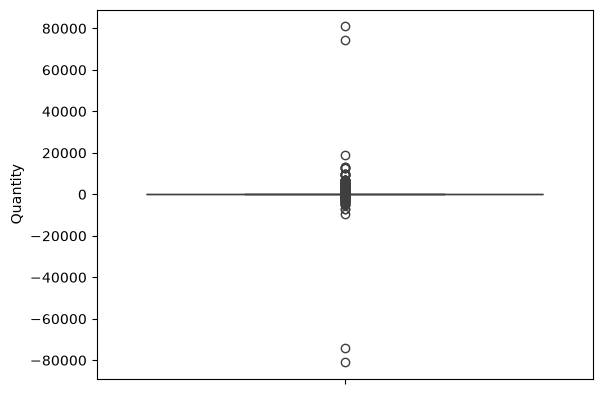

In [15]:
sns.boxplot(df['Quantity'])

In [16]:
# Removing Return Material from the dataset

df['Qty_abs']=df['Quantity'].abs()
df['Type']=np.where(df['Quantity']>0,'buy','return')
keys=['Customer ID','StockCode','Qty_abs']
df['n']=df.groupby(keys + ['Type']).cumcount()
df['pair']=df.groupby(keys + ['n'])['Type'].transform('nunique')
df=df[(df['pair']==1) & (df['Quantity']>0)].copy()

In [17]:
df['Price'].skew()

np.float64(221.9347103631327)

<Axes: ylabel='Price'>

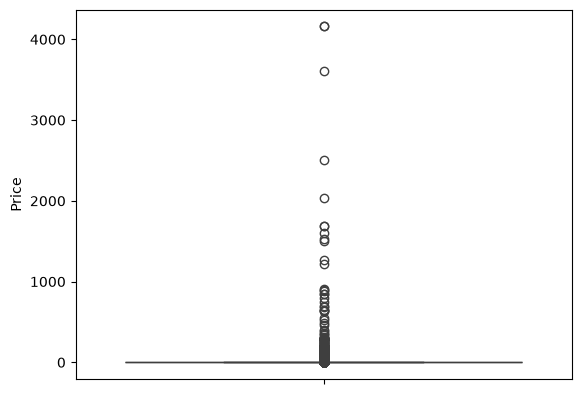

In [18]:
sns.boxplot(df['Price'])

In [19]:
df[df['Price']>1600]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Total_price,Qty_abs,Type,n,pair
288706,517483,M,Manual,1,2010-07-29 12:29:00,3610.50,12737,France,3610.50,1,buy,0,1
642515,546328,M,Manual,1,2011-03-11 10:19:00,1687.17,14911,EIRE,1687.17,1,buy,17,1
642516,546329,M,Manual,1,2011-03-11 10:22:00,1687.17,14911,EIRE,1687.17,1,buy,18,1
822899,562946,M,Manual,1,2011-08-11 09:38:00,2500.00,15581,United Kingdom,2500.00,1,buy,5,1
868458,566927,M,Manual,1,2011-09-15 15:20:00,2033.10,17846,United Kingdom,2033.10,1,buy,0,1
947835,573077,M,Manual,1,2011-10-27 14:13:00,4161.06,12536,France,4161.06,1,buy,0,1
947838,573080,M,Manual,1,2011-10-27 14:20:00,4161.06,12536,France,4161.06,1,buy,1,1


In [20]:
# Checking Non-Realistic StockCode

non_product=df[~df['StockCode'].astype(str).str.match(r'^\d{5}')]
non_product['StockCode'].value_counts()

StockCode
POST            1744
M                546
C2               242
ADJUST            31
BANK CHARGES      29
PADS              17
DOT               16
TEST001           11
D                  3
ADJUST2            3
SP1002             2
TEST002            1
Name: count, dtype: int64

In [21]:
# Removing Non-Realistic StockCode from data

remove=['POST','M','C2','ADJUST','BANK CHARGES','PADS','DOT','TEST001','D','ADJUST2','SP1002','TEST002']
df=df[~df['StockCode'].isin(remove)].copy()

In [22]:
# Creating a new dataframe 'df_rfm' with the columns 'Customer ID', 'Frequency', 'Monetary' and 'Recency'

last_date=df['InvoiceDate'].max()

snapshot_date=last_date+pd.DateOffset(days=1)
snapshot_date

df_rfm=df.groupby('Customer ID').agg(
    Frequency=("Invoice",'nunique'),
    Monetary=("Total_price","sum"),
    Recency=('InvoiceDate',lambda x: (snapshot_date - x.max()).days)
    ).reset_index()

In [23]:
# Overview of the new dataframe 'df_rfm'

df_rfm.head()

,Customer ID,Frequency,Monetary,Recency
0,12346,2,169.36,529
1,12347,8,4921.53,2
2,12348,5,1658.40,75
3,12349,3,3678.69,19
4,12350,1,294.40,310


In [24]:
# Generating RFM Scores and Segments

r_score=[]
for i in df_rfm['Recency']:
    if i<30:
         r_score.append(5)
    elif i>=30 and i<60:
         r_score.append(4)
    elif i>=60 and i<90:
         r_score.append(3)
    elif i>=90 and i<120:
         r_score.append(2)
    else:
         r_score.append(1)
df_rfm['R_Score']=r_score

f_score=[]
for i in df_rfm['Frequency']:
    if i>=10:
         f_score.append(5)
    elif i>=8 and i<10:
         f_score.append(4)
    elif i>=6 and i<8:
         f_score.append(3)
    elif i>=4 and i<6:
         f_score.append(2)
    else:
         f_score.append(1)
df_rfm['F_Score']=f_score

m_score=[]
for i in df_rfm['Monetary']:
    if i>=1000:
         m_score.append(5)
    elif i>=800 and i<1000:
         m_score.append(4)
    elif i>=600 and i<800:
         m_score.append(3)
    elif i>=400 and i<600:
         m_score.append(2)
    else:
         m_score.append(1)
df_rfm['M_Score']=m_score

segments=[]
for r,f,m in zip(df_rfm['R_Score'],df_rfm['F_Score'],df_rfm['M_Score']):
     if r>=4 and f>=4 and m>=4:
          segments.append('Champions')
     elif r>=3 and f>=3 and m>=3:
          segments.append('Loyal')
     elif r<=2 and f<=2 and m<=2:
          segments.append('Lost')
     elif r<=2 and f>=4 and m>=4:
          segments.append("Can't Lose")
     else:
          segments.append('At-risk')
df_rfm['Segment']=segments

In [25]:
df_rfm.head()


,Customer ID,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,Segment
0,12346,2,169.36,529,1,1,1,Lost
1,12347,8,4921.53,2,5,4,5,Champions
2,12348,5,1658.40,75,3,2,5,At-risk
3,12349,3,3678.69,19,5,1,5,At-risk
4,12350,1,294.40,310,1,1,1,Lost


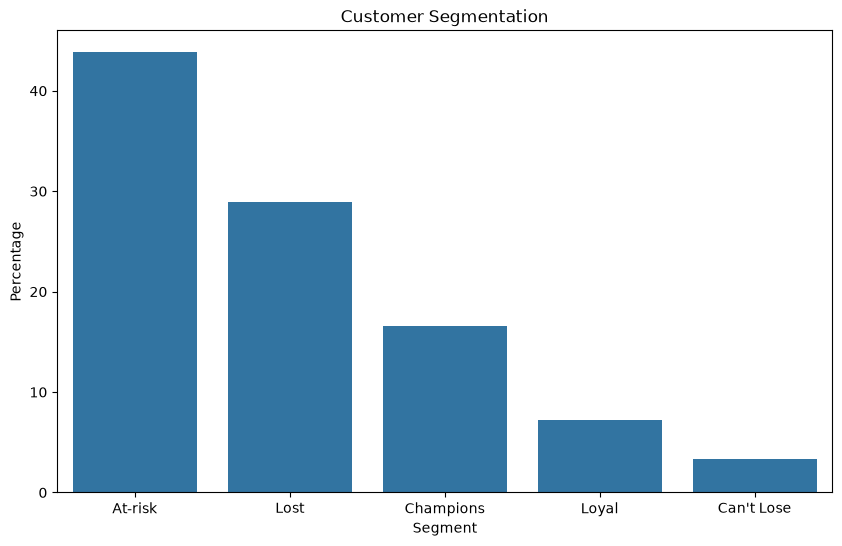

In [26]:
# Visualize percent of diffrent segments

Segment_Percentage=df_rfm['Segment'].value_counts(normalize=True)*100
fig,ax=plt.subplots(figsize=(10,6))
sns.barplot(x=Segment_Percentage.index,y=Segment_Percentage.values,ax=ax)
plt.xlabel('Segment')
plt.ylabel('Percentage')
plt.title('Customer Segmentation')

plt.show()

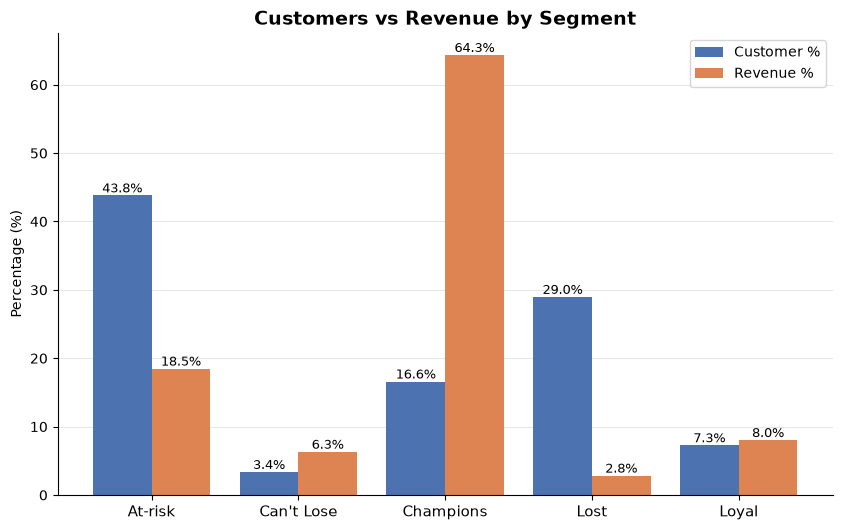

,Segment,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Revenue %,customer %
0,At-risk,2556,152.848592,3.101721,1192.268259,3.0M,18.48,43.812136
1,Can't Lose,196,214.821429,13.331633,5312.961633,1.0M,6.32,3.359616
2,Champions,968,18.367769,20.595041,10959.678740,10.6M,64.35,16.592389
3,Lost,1690,413.468639,1.472781,276.029580,466.5K,2.83,28.968118
4,Loyal,424,42.155660,7.882075,3120.858632,1.3M,8.03,7.267741


In [27]:
# Creating summary of segments and visualize how segments affects revenue % and customer %

def format_func(value):
    if value>=1e6:
        return f'{value/1e6:.1f}M'
    elif value>=1e3:
        return f'{value/1e3:.1f}K'
    else:
        return f'{value:.0f}'

summary=df_rfm.groupby("Segment").agg(
    Customer_Count=('Customer ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index()

summary['Revenue %'] = (summary['Total_Revenue']/ summary['Total_Revenue'].sum())*100
summary['customer %']= (summary['Customer_Count']/ summary['Customer_Count'].sum())*100
summary['Total_Revenue'] = summary['Total_Revenue'].apply(format_func)
summary['Revenue %'] = summary['Revenue %'].apply(lambda x: f'{x:.2f}')
summary['Revenue %']=summary['Revenue %'].astype(float)

fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(summary))
b1 = ax.bar([i - 0.2 for i in x], summary['customer %'], width=0.4, label='Customer %', color='#4C72B0')
b2 = ax.bar([i + 0.2 for i in x], summary['Revenue %'], width=0.4, label='Revenue %', color='#DD8452')

ax.bar_label(b1, fmt='%.1f%%', fontsize=9)
ax.bar_label(b2, fmt='%.1f%%', fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(summary['Segment'], fontsize=11)
ax.set_ylabel('Percentage (%)')
ax.set_title('Customers vs Revenue by Segment', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.show()
summary

In [28]:
# Overall Analysis and Summary

# This analysis segmented 5,878 customers using RFM (Recency, Frequency, Monetary) and used each segment's share of customers and revenue to recommend a marketing budget allocation.

# Champions (16.6% of customers, 64.3% of revenue): 50% of budget
# Fewer than one in five customers generate nearly two-thirds of total revenue. Retaining them offers the highest return on investment, so they receive the largest share through rewards, early access and loyalty benefits.

# At-Risk (43.8% of customers, 18.5% of revenue): 20% of budget
# This is the largest segment, but it contributes less than a fifth of revenue. These customers purchased relatively recently (average recency of about 155 days), so they can still be won back with reminder emails and targeted discounts.

# Can't Lose (3.4% of customers, 6.3% of revenue): 15% of budget
# This is a small group of customers who spent heavily in the past (about £5,840 on average) but have been inactive for a long time. The cost of reaching them is low relative to their value, so they receive personalised outreach and special offers.

# Loyal (7.3% of customers, 8.0% of revenue): 10% of budget
# These customers are stable and already engaged. A modest budget is enough to keep them satisfied and protect their revenue.

# Lost (29.0% of customers, 2.8% of revenue): 5% of budget
# This segment has a large customer base but contributes very little revenue. Only low-cost campaigns, such as a periodic win-back email, are recommended.

# Conclusion
# Budget is allocated according to each segment's revenue contribution and its potential for recovery. Any expected revenue improvement from this plan is an assumption and should be validated through testing.

In [29]:
# Exporting to Power BI for dashboard

df_rfm.to_csv('rfm_segments.csv',index=False)
summary.to_csv('rfm_summary.csv',index=False)

